# Dataset Hypothyroid

##  importation des bibliotheques

In [42]:
!pip install kmedoids


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\User\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [1]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\User\anaconda3\python.exe
3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]


In [2]:
import sys
!{sys.executable} -m pip install kmedoids

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from scipy.io import arff
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import kmedoids
from sklearn.metrics.pairwise import euclidean_distances
# from sklearn.metrics.pairwise import euclidean_distances

###  1-lire et afficher le dataset


In [43]:

data, meta= arff.loadarff("hypothyroid.arff")

df = pd.DataFrame(data)

# Converting the text data into string format
for c in df.columns:
    df[c] = df[c].apply(
        lambda x: x.decode("utf-8") if isinstance(x, bytes) else x
    )

display(df)

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,...,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,Class
0,41.0,F,f,f,f,f,f,f,f,f,...,t,125.0,t,1.14,t,109.0,f,NaN,SVHC,negative
1,23.0,F,f,f,f,f,f,f,f,f,...,t,102.0,f,NaN,f,NaN,f,NaN,other,negative
2,46.0,M,f,f,f,f,f,f,f,f,...,t,109.0,t,0.91,t,120.0,f,NaN,other,negative
3,70.0,F,t,f,f,f,f,f,f,f,...,t,175.0,f,NaN,f,NaN,f,NaN,other,negative
4,70.0,F,f,f,f,f,f,f,f,f,...,t,61.0,t,0.87,t,70.0,f,NaN,SVI,negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3767,30.0,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,negative
3768,68.0,F,f,f,f,f,f,f,f,f,...,t,124.0,t,1.08,t,114.0,f,NaN,SVI,negative
3769,74.0,F,f,f,f,f,f,f,f,f,...,t,112.0,t,1.07,t,105.0,f,NaN,other,negative
3770,72.0,M,f,f,f,f,f,f,f,f,...,t,82.0,t,0.94,t,87.0,f,NaN,SVI,negative


### 1. Identifier et supprimer les attributs ayant plus de 60 % de valeurs manquantes

In [44]:
# Calculer le pourcentage de valeurs manquantes
pourcentage_nan = df.isnull().mean() * 100

# Identifier les attributs ayant plus de 70% de valeurs manquantes
cln_vides = pourcentage_nan[pourcentage_nan > 70].index.tolist()
# Supprimer ces attributs

df = df.drop(columns=cln_vides)
print("Attributs  supprimée :", cln_vides)

Attributs  supprimée : ['TBG']


### Supprission des doublons:

In [45]:
df = df.drop_duplicates()

### Remplacement des outliers par lim inf ou lim sup

In [46]:
# select num attributs
numeriques_df = df.select_dtypes(include=np.number)

for col in numeriques_df.columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR

    # Remplacer les outliers par les limites
    df[col] = df[col].clip(lower=limite_inf, upper=limite_sup)

### 2. Gestion des valeurs manquantes:

- Identification:

In [47]:
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']


- Remplacement

In [48]:
# Selectionner a nouveau les attributs numeriques pour avoir les changer
numeriques_df = df.select_dtypes(include=np.number)

# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:
    if col not in df.columns:
        continue

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:
        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)


[]


#### Z-score :

In [49]:
# Selectionner les attributs numeriques apres le nettoyage
numeriques_df = df.select_dtypes(include=np.number)
# Standardisation
scaler = StandardScaler()
scaled_dataset = scaler.fit_transform(numeriques_df)

# Convertir le resultat en DataFrame
scaled_dataset = pd.DataFrame(scaled_dataset, columns=numeriques_df.columns)

display(scaled_dataset)

,age,TSH,T3,TT4,T4U,FTI
0,-0.566001,-3.611203e-01,8.457333e-01,0.593982,9.649523e-01,-0.016711
1,-1.512111,1.199865e+00,3.549709e-02,-0.176568,6.997527e-16,0.000000
2,-0.303193,-5.395186e-01,3.598172e-16,0.057947,-4.846944e-01,0.412549
3,0.958287,-9.966642e-01,-1.265502e-01,2.269088,6.997527e-16,0.000000
4,0.958287,-6.844672e-01,-1.260881e+00,-1.550155,-7.368069e-01,-1.538632
...,...,...,...,...,...,...
3706,-1.144179,-1.237887e-16,3.598172e-16,0.000000,6.997527e-16,0.000000
3707,0.853163,-5.283687e-01,1.975443e-01,0.560479,5.867836e-01,0.178407
3708,1.168533,1.757359e+00,-2.885974e-01,0.158454,5.237554e-01,-0.172806
3709,1.063410,-6.956171e-01,3.549709e-02,-0.846610,-2.956101e-01,-0.875231


### Courbe D'elbow

1. Calculer l'inertie pour chaque valeur de k

In [50]:
kmeans_inerties = []

# Tester k de 1 a 10
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_dataset)
    kmeans_inerties.append(kmeans.inertia_)

2. Tracer la courbe d'elbow

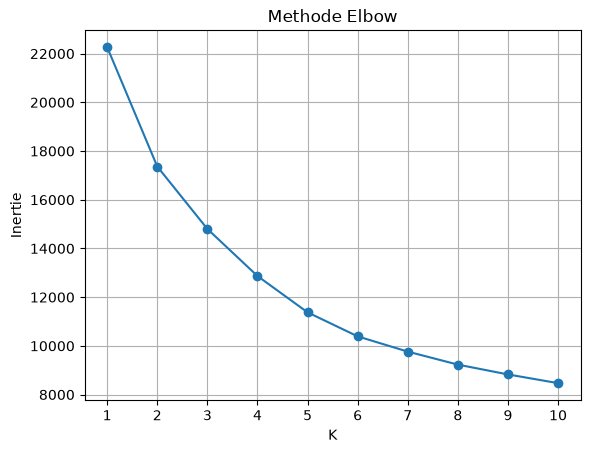

In [51]:
import matplotlib.pyplot as plt

plt.plot(K, kmeans_inerties, marker='o')

plt.xlabel("K")
plt.ylabel("Inertie")
plt.title("Methode Elbow")

plt.xticks(K)
plt.grid()
plt.show()

### Algorithme KMeans

1. Application de l'algo

In [52]:
# selon le graphique, le nombre optimal de clusters est 4
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(scaled_dataset)

# Ajouter les clusters aux donnees
clusters = kmeans.labels_

print("Les clusters :", clusters)

Les clusters : [1 0 2 ... 0 2 2]


recuperer l'inertie 

In [70]:
inertie_kmeans = kmeans.inertia_

print("Inertie K-Means :", inertie_kmeans)


Inertie K-Means : 14802.528721107978


2. Afficher le nombre d'elements dans chaque cluster

In [61]:
print(pd.Series(clusters).value_counts().sort_index())

0     570
1     975
2    2166
Name: count, dtype: int64


3. Coef de Silhouette

In [76]:
score_Kmedian = silhouette_score(scaled_dataset, clusters)
print("Coefficient de silhouette :", score_Kmedian)

Coefficient de silhouette : 0.22116527714205583


4. Interpretation des resutats:

Le coefficient de silhouette permet d'évaluer la qualité du clustering en mesurant la cohésion des observations au sein de leurs clusters et la séparation entre les différents clusters.

Pour K = 4, le coefficient obtenu est de 0,183 , ce qui indique une faible séparation entre les clusters.

En revanche, pour K = 3, le coefficient atteint 0,22. Cette amélioration indique une meilleure organisation des données en clusters, avec une séparation plus satisfaisante entre les groupes.

Ainsi, parmi ces deux configurations, K = 3 présente le meilleur résultat selon le coefficient de silhouette. Cependant, la qualité du clustering reste modérée et les groupes ne sont pas parfaitement séparés.

# 4. K-Medoids

Calculer la matrice des distances

In [63]:
# Calculer la matrice des distances euclidiennes
distances = euclidean_distances(scaled_dataset)

Appliquer KMedoid

In [64]:
# Appliquer K-Medoids avec 3 clusters
kmedoids_instance = kmedoids.KMedoids(
    n_clusters=3,
    method="fasterpam"
)

kmedoids_instance.fit(distances)
# Recuperer les clusters
clusters_kmedoids = kmedoids_instance.labels_

# Afficher les clusters
print("Les clusters :", clusters_kmedoids)



Les clusters : [2 1 2 ... 1 0 0]


Afficher le nombre d'observations dans chaque cluster

In [65]:

print(pd.Series(clusters_kmedoids).value_counts().sort_index())

0    1400
1     635
2    1676
Name: count, dtype: int64


Afficher les Medoids

In [66]:
print("Indices des medoids :")
print(kmedoids_instance.medoid_indices_)

Indices des medoids :
[  51   41 2573]


Calculer le Ceof de Silhouette

In [67]:
# Calculer le coefficient de silhouette
score_kmedoids = silhouette_score(scaled_dataset,clusters_kmedoids)

print("Coefficient de silhouette K-Medoids :", score_kmedoids)

Coefficient de silhouette K-Medoids : 0.17290379609287723


Analyse des Resultats

In [77]:
print("Silhouette K-Means :", score_Kmedian)
print("Silhouette K-Medoids :", score_kmedoids)

Silhouette K-Means : 0.22116527714205583
Silhouette K-Medoids : 0.17290379609287723


**WE SHOULD ADD A COMMENT**

### 5.Comparaison des performances : 

5.1.Histogramme des inerties : 

calculer l'inertie de K-Medoids

In [78]:
inertie_kmedoids = kmedoids_instance.inertia_

print("Inertie K-Medoids :", inertie_kmedoids)

Inertie K-Medoids : 6993.431826404764


Creer l'histogramme

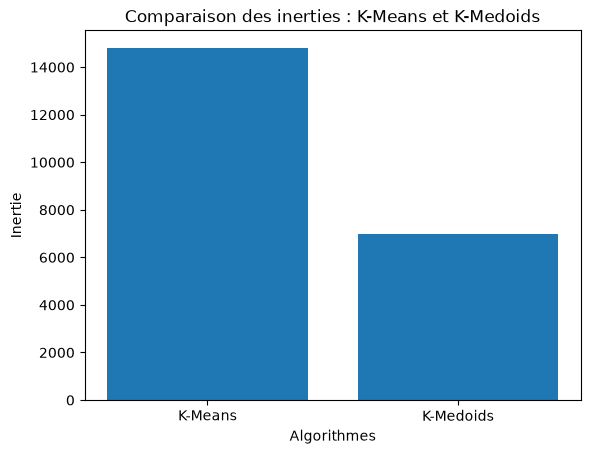

In [79]:
methodes = ["K-Means", "K-Medoids"]
inerties = [inertie_kmeans, inertie_kmedoids]

plt.bar(methodes, inerties)
plt.xlabel("Algorithmes")
plt.ylabel("Inertie")
plt.title("Comparaison des inerties : K-Means et K-Medoids")

plt.show()